# Lab 3.10 — How does a pretrained model adapt?

Continue training the small dense base on uppercase dialogue. This deliberate change makes adaptation measurable using the same character vocabulary. Keep the final tenth of the corpus for evaluation.

## Fine-tune on a controlled change

Use 120 batches from a fresh slice of the text. Score uppercase held-out windows before the first update and every twenty updates. Predict what happens to the model’s preference for lowercase continuations.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch import nn
from llm_lab.experiments import record, show

torch.manual_seed(34)
torch.set_num_threads(1)

from llm_lab.experiments import loads_base, fit_adaptation
model,alphabet = loads_base()
initial = model.h[0].attn.c_attn.weight.detach().clone()
scores,trainable,state_bytes = fit_adaptation(model,alphabet,lr=.002)
delta = model.h[0].attn.c_attn.weight.detach()-initial
print("Trainable parameters, AdamW state bytes:",trainable,state_bytes)
print("Held-out nats per character:",scores[0],"→",scores[-1])

Trainable parameters, AdamW state bytes: 28576 228720
Held-out nats per character: 4.835925579071045 → 2.7133333683013916


## Is a full update concentrated in a few directions?

The singular values of the change in the first QKV projection measure how much it stretches vectors along orthogonal directions. The first four squared singular values divided by the total squared sum give the fraction of update energy captured by its best rank-four approximation. Predict this number before plotting it. How much does this one matrix tell you about the other layers?

Rank-four fraction: 0.49221575260162354
Out[2]: PosixPath('checkpoints/lab310/full_tune.npz')


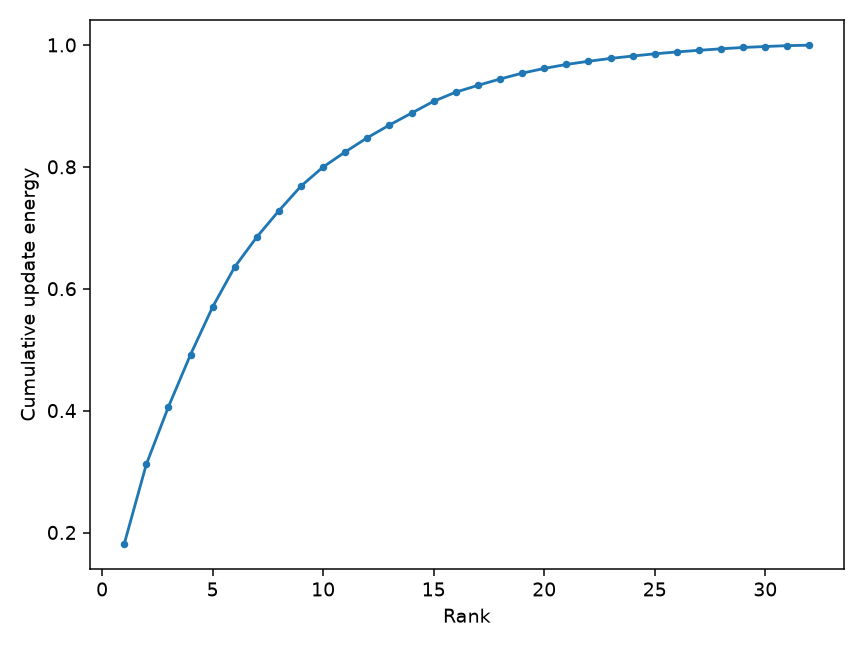

In [2]:
sigma = torch.linalg.svdvals(delta)
energy = sigma.square().cumsum(0)/sigma.square().sum()
print("Rank-four fraction:",energy[3].item())
plt.plot(range(1,len(energy)+1),energy,marker="."); plt.xlabel("Rank"); plt.ylabel("Cumulative update energy")
show(310,"update_rank")
record(310,"full_tune",scores=scores,trainable=trainable,state_bytes=state_bytes,
       singular_values=sigma,**{k:v.detach() for k,v in model.state_dict().items()})

## Reading the result

Full tuning reduced uppercase held-out loss from 4.84 to 2.71 nats per character. Four singular directions accounted for 49% of the squared change in the first QKV matrix. In Lab 3.11 you can test how well a model learns when it must choose four update directions during training.